# **POST STRUCTURE ANALYSIS**

## Reading data

In [1]:
PATH_DATA = "/home/meritxell/Bioinformatica/ERASMUS/DM/Project/Cleaned_data/"
data = {
    "entries": {
        "files": [
            PATH_DATA+"entries_cleaned.csv",
        ],
        "columns": [
            "EntryID",
            "PostedBy",
            "SourceName",
            "SourceURL",
            "Text",
            "NumImg",
            "ImgURL",
            "NumVid",
            "VidURL",
        ],
        "sep": "\t",
        "df": None,
        "skipped": 0,
    },
    "comments": {
        "files": [
            PATH_DATA+"comments_cleaned.csv"
        ],
        "columns": [
            "CommentID",
            "EntryID",
            "PostedBy",
            "SourceName",
            "SourceURL",
            "Text",
        ],
        "sep": "\t",
        "df": None,
        "skipped": 0,
    },
    "followers": {
        "files": [
            PATH_DATA+"following_cleaned.csv"
        ],
        "columns": ["FollowedID", "FollowerID"],
        "sep": "\t",
        "df": None,
        "skipped": 0,
    },
    "likes": {
        "files": [
            PATH_DATA+"likes_cleaned.csv"
        ],
        "columns": ["UserID", "EntryID"],
        "sep": "\t",
        "df": None,
        "skipped": 0,
    },
    "users": {
        "files": [
            PATH_DATA+"users_cleaned.csv"
        ],
        "columns": ["ID", "Type", "Name"],
        "sep": "|",
        "df": None,
        "skipped": 0,
    },
}


### Loading data to database

In [ ]:
import pandas as pd
import sqlite3
import matplotlib.pyplot as plt
import seaborn as sns # Using seaborn as it allows to build boxplots with the previous table generated


def load_to_sqlite(df_files, columns, table_name, conn, sep="\t", chunksize=50_000 ):
    
    total_rows = 0

    for file in df_files:

        reader = pd.read_csv(
            file,
            sep=sep,
            header=None,
            names=columns,
            na_values=["\\N"],
            on_bad_lines="skip",
            chunksize=chunksize
        )

        for chunk in reader:

            chunk.to_sql(
                table_name,
                conn,
                if_exists="append",
                index=False
            )

            total_rows += len(chunk)

            print(
                f"\rLoading {table_name}... "
                f"{total_rows:,} rows",
                end="",
                flush=True
            )

    print(f"\rLoaded {table_name}. Rows: {total_rows:,}")

    return total_rows

/home/meritxell/anaconda3/lib/python3.13/site-packages/pandas/core/computation/expressions.py:23: UserWarning: Pandas requires version '2.10.2' or newer of 'numexpr' (version '2.10.1' currently installed).
  from pandas.core.computation.check import NUMEXPR_INSTALLED


In [4]:
# Generating connection to database
DB_PATH = "/home/meritxell/Bioinformatica/ERASMUS/DM/Project/DMProjectDB_cleaned2.db"
conn = sqlite3.connect(DB_PATH)

In [5]:
## THIS IS ONLY RUN ONCE TO GENERATE THE DATABASE FILE
for dataset_name, dataset in data.items():
    
    conn.execute(f'DROP TABLE IF EXISTS "{dataset_name}"')

    load_to_sqlite(
        df_files=dataset["files"],
        columns=dataset["columns"],
        table_name=dataset_name,
        conn=conn,
        sep=dataset["sep"],
        chunksize=50_000
    )

Loaded entries. Rows: 11,043,310ws
Loaded comments. Rows: 2,675,666ws
Loaded followers. Rows: 18,837,043ws
Loaded likes. Rows: 446,605ws
Loaded users. Rows: 651,870ws


## Variable checking

From the build database, generating a table containing all entries and their information. Including counts of images, videos, comments and likes and number of followers for the user

In [6]:
## Generating a whole table with all the information for each entry
creating_big_table = """CREATE TABLE entries_analysis AS 
WITH like_counts AS (SELECT EntryID, COUNT(*) AS NumLikes FROM likes
GROUP BY EntryID),
comment_counts AS (SELECT EntryID, COUNT(*) AS NumComments 
FROM comments GROUP BY EntryID),
follower_counts AS (SELECT FollowedID, COUNT(*) AS NumFollowers
FROM followers GROUP BY FollowedID)
SELECT e.EntryID, e.PostedBy, e.SourceName, e.SourceURL, e.Text,
e.NumImg, e.ImgURL, e.NumVid,
COALESCE(l.NumLikes, 0) AS NumLikes, COALESCE(c.NumComments, 0) AS NumComments,
u.Type AS UserType,
u.Name AS UserName,
COALESCE(f.NumFollowers, 0) AS NumFollowers
FROM entries e
LEFT JOIN like_counts l
ON e.EntryID = l.EntryID
LEFT JOIN comment_counts c
ON e.EntryID = c.EntryID
LEFT JOIN users u
ON e.PostedBy = u.ID
LEFT JOIN follower_counts f
ON e.PostedBy = f.FollowedID
"""
conn.execute(creating_big_table)
conn.commit()

### Checking variables types

As it was seen that number of images and number of videos could contain NaN values as None, we are checking that all of those values are converted to 0.   
This is not an assumption, this is a fact as if Image = None corresponds to an entry havin 0 images.

In [7]:
# Checking datatypes for NumImg
test_query = """
SELECT EntryID, NumImg, typeof(NumImg) AS type
FROM entries_analysis
WHERE typeof(NumImg) != 'real';
"""
pd.read_sql_query(test_query, conn)
# 89 rows contained None as NumImg

,EntryID,NumImg,type
0,e/88e1992e58469fcf81abb79b30cfde3c,None,null
1,e/f28f5c676589e3143baab78a46bfac6a,None,null
2,e/eaab037157c934e79cafba128c3a402e,None,null
3,e/b0289ad6acb00ea7117f18eaa1c8700a,None,null
4,e/8adb7b85ff01156fa54e87cd70fa3486,None,null
...,...,...,...
84,e/e986c05418f081290ae4b949baf7e003,None,null
85,e/34c77ba9487e122c51f2d6b5c3382a06,None,null
86,e/0846cf418c57bd6f615c43a0a63d7558,None,null
87,e/7e26dda0a5c41d10b531cdd14679c070,None,null


In [8]:
# Checking datatypes for NumVid
check_query = """
SELECT EntryID, NumVid, typeof(NumVid) AS type
FROM entries_analysis
WHERE typeof(NumVid) != 'real' OR NumVid = 'None';
"""
prova = pd.read_sql_query(check_query, conn)
display(prova)

,EntryID,NumVid,type
0,e/88e1992e58469fcf81abb79b30cfde3c,None,null
1,e/f28f5c676589e3143baab78a46bfac6a,None,null
2,e/eaab037157c934e79cafba128c3a402e,None,null
3,e/b0289ad6acb00ea7117f18eaa1c8700a,None,null
4,e/8adb7b85ff01156fa54e87cd70fa3486,None,null
...,...,...,...
84,e/e986c05418f081290ae4b949baf7e003,None,null
85,e/34c77ba9487e122c51f2d6b5c3382a06,None,null
86,e/0846cf418c57bd6f615c43a0a63d7558,None,null
87,e/7e26dda0a5c41d10b531cdd14679c070,None,null


In [9]:
# Updating those entries to 0 and real type
conn.execute("""UPDATE entries_analysis SET NumImg = 0.0
WHERE NumImg IS NULL;""")
conn.execute("""UPDATE entries_analysis SET NumVid = 0.0
WHERE NumVid IS NULL;""")
conn.commit()

In [10]:
check_q = """
SELECT
typeof(NumImg) AS ImgType,
typeof(NumVid) AS VidType,
COUNT(*) AS NumEntries
FROM entries_analysis
GROUP BY typeof(NumImg), typeof(NumVid);
"""
check = pd.read_sql_query(check_q, conn)
display(check)

,ImgType,VidType,NumEntries
0,real,real,11043310


In [12]:
# Showing how the table is organized
query_snip_table = "SELECT * FROM entries_analysis LIMIT 5"
snip_table = pd.read_sql_query(query_snip_table, conn)
display(snip_table)

,EntryID,PostedBy,SourceName,SourceURL,Text,NumImg,ImgURL,NumVid,NumLikes,NumComments,UserType,UserName,NumFollowers
0,e/29af803d670fb8d67692095f3ee623e6,newsroom1,Ottawa Citizen - News,http://www.ottawacitizen.com/index.html,RIM 'will not compromise' BlackBerry security ...,1.0,http://www.ottawacitizen.com/will+compromise+...,0.0,0,1,group,NewsROOM,36
1,e/9c8413a376bec6389be4d46d0812c2bb,mehmetinnet,Mehmetin.Net,http://www.mehmetin.net,Fethullah Gülen: Referandum siyasî olarak görü...,1.0,http://www.mehmetin.net/2010/08/fethullah-gul...,0.0,0,0,user,Mehmetin.Net,36
2,e/2d658d97842a466a9513f587f85b0e59,mehmetergin,Mehmetin.Net,http://www.mehmetin.net/,Fethullah Gülen: Referandum siyasî olarak görü...,1.0,http://www.mehmetin.net/2010/08/fethullah-gul...,0.0,0,0,user,Mehmet Ergin,1
3,e/b269ab5d56be4e5e90c1954ecc1ef63a,afriki,NaN,NaN,Мне тут недавно один дизайнер сказал: «Ну прот...,0.0,NaN,0.0,6,49,user,Африки,230
4,e/74f0a50c374a4ad6bddcbcc60c60cad9,hamsafar,NaN,NaN,عرض سلام و خسته نباشيد:),0.0,NaN,0.0,4,32,user,Hamsafar,476


In this final script we are not including the plots generated for the preliminary steps as it was just for our understandment of the data, they are not part of the final result.

## Attention table creation

Creating a table in the database containing only attention entries.  
As these entries are a small proportion of the whole data but at the same time are the ones we want to focus on for our study, we decided to work only with them. So we are taking entries that have at least 1 comment or at least 1 like.  
Our aim is to find what do these entries contain that make them receive attention

In [13]:
table_arm_query = """CREATE TABLE entries_attention AS 
SELECT * FROM entries_analysis WHERE NumLikes > 0 OR NumComments > 0;"""
conn.execute(table_arm_query)

In [14]:
snip_table_attention = "SELECT * FROM entries_attention LIMIT 5"
display(pd.read_sql_query(snip_table_attention, conn))

,EntryID,PostedBy,SourceName,SourceURL,Text,NumImg,ImgURL,NumVid,NumLikes,NumComments,UserType,UserName,NumFollowers
0,e/29af803d670fb8d67692095f3ee623e6,newsroom1,Ottawa Citizen - News,http://www.ottawacitizen.com/index.html,RIM 'will not compromise' BlackBerry security ...,1.0,http://www.ottawacitizen.com/will+compromise+...,0.0,0,1,group,NewsROOM,36
1,e/b269ab5d56be4e5e90c1954ecc1ef63a,afriki,NaN,NaN,Мне тут недавно один дизайнер сказал: «Ну прот...,0.0,NaN,0.0,6,49,user,Африки,230
2,e/74f0a50c374a4ad6bddcbcc60c60cad9,hamsafar,NaN,NaN,عرض سلام و خسته نباشيد:),0.0,NaN,0.0,4,32,user,Hamsafar,476
3,e/38867ca7a6b80722345569a30c1cf2d4,sconfinando,La casa sull'albero,http://sandalialsole.blogspot.com,"A volte succede - <a rel=""nofollow"" href=""http...",0.0,NaN,0.0,0,5,user,sconfinando,23
4,e/5e7ad669ceac4b11b741c353ee4458e2,dengesizyay,NaN,NaN,"<a href=""http://friendfeed.com/search?q=%23twi...",0.0,NaN,0.0,2,5,user,dengesizyay,452


To combine both likes and attention, we are generating a column representing the total attention adding the number of likes and the number of comments. To simplify things we are making the attention score as `number of likes` + `number of comments`.

In [15]:
conn.execute("""ALTER TABLE entries_attention ADD COLUMN Attention INTEGER;""")
conn.execute("""UPDATE entries_attention 
SET Attention = NumLikes + NumComments;""")
conn.commit()

## Discretization on Attention score

Reading the table to analyse how the discretization can be applied

In [16]:
table_attention_q = "SELECT EntryID, PostedBy, NumImg, ImgURL, NumVid, Attention " \
" FROM entries_attention"
table_attention = pd.read_sql_query(table_attention_q, conn)

Now we are applying discretization on the Attention score, so we can classify based on:
- Low attention
- Medium attention
- High attention

In [17]:
# Seeing how categories can be distributed
table_attention["Attention"].describe(
    percentiles=[0.25, 0.5, 0.75, 0.90, 0.95, 0.99]
)

count    1.170682e+06
mean     2.618371e+00
std      9.725218e+00
min      1.000000e+00
25%      1.000000e+00
50%      1.000000e+00
75%      1.000000e+00
90%      5.000000e+00
95%      9.000000e+00
99%      2.700000e+01
max      4.099000e+03
Name: Attention, dtype: float64

This allows to see that we have a right tailed distribution, as 75% of the entries contain only an attention score of 1.  
- Low attention: 1, this will take around 75% of the entries
- Medium attention: 2-5 , this will take around 15% of the entries
- High attention: +5, this will take 10% of the entries

In [18]:
# Creating new column for attention as a categorical variable
conn.execute("""ALTER TABLE entries_attention ADD COLUMN Attention_category VARCHAR(20);""")
conn.commit()

In [19]:
conn.execute("""UPDATE entries_attention SET Attention_category = 
CASE WHEN Attention = 1 THEN 'Low' WHEN Attention <=5 THEN 'Medium' 
ELSE 'High' END; """)
conn.commit()

In [20]:
check_att_q = """SELECT Attention_category, COUNT(*) AS NumEntries
FROM entries_attention GROUP BY Attention_category ORDER BY MIN(Attention)"""
pd.read_sql_query(check_att_q, conn)

,Attention_category,NumEntries
0,Low,903736
1,Medium,157789
2,High,109157


## Discretization of NumImages and NumVideos

Visualizing the distribution based on `NumImg` to infer the possible categories

In [21]:
img_counts = (table_attention['NumImg'].value_counts(normalize=True).sort_index().mul(100))
img_counts

NumImg
0.0     80.642309
1.0     15.526847
2.0      1.933488
3.0      1.129000
4.0      0.192708
5.0      0.118222
6.0      0.083370
7.0      0.057573
8.0      0.042966
9.0      0.033912
10.0     0.032887
11.0     0.022209
12.0     0.021782
13.0     0.015546
14.0     0.012557
15.0     0.013838
16.0     0.010336
17.0     0.011190
18.0     0.008713
19.0     0.006150
20.0     0.028701
21.0     0.005296
22.0     0.003588
23.0     0.003331
24.0     0.003844
25.0     0.039635
Name: proportion, dtype: float64

We are applying discretization to get different categories for the number of images in an entry:
- No images: 0
- Single image: 1
- Few images: 2-3
- Many images: 4+

In [22]:
conn.execute("""ALTER TABLE entries_attention ADD COLUMN ImgCountGroup VARCHAR(20);""")
conn.execute("""UPDATE entries_attention SET ImgCountGroup = CASE
WHEN NumImg = 0 THEN 'No images' WHEN NumImg = 1 THEN '1 image' 
WHEN NumImg BETWEEN 2 AND 3 THEN '2-3 images' WHEN NumImg >=4 THEN '4+ images' END;""")                                            

Visualizing the resulting categories for Images

In [23]:
grouping_images_q = """SELECT ImgCountGroup, COUNT(*) AS NumEntries
FROM entries_attention GROUP BY ImgCountGroup ORDER BY MIN(NumImg)"""
grouping_images = pd.read_sql_query(grouping_images_q, conn)
grouping_images

,ImgCountGroup,NumEntries
0,No images,944065
1,1 image,181770
2,2-3 images,35852
3,4+ images,8995


Repeating the procedure but for number of videos in entries

In [24]:
vid_counts = (table_attention['NumVid'].value_counts(normalize=True).sort_index().mul(100))
vid_counts

NumVid
0.0     98.466279
1.0      1.380990
2.0      0.148546
3.0      0.002648
4.0      0.000940
5.0      0.000171
7.0      0.000085
8.0      0.000171
9.0      0.000085
10.0     0.000085
Name: proportion, dtype: float64

As in this case there are fewer entries containing 1 or more videos, we have decided to group based on the presence or not of videos.

In [25]:
conn.execute("""ALTER TABLE entries_attention ADD COLUMN VidCountGroup VARCHAR(20);""")
conn.execute("""UPDATE entries_attention SET VidCountGroup = CASE
WHEN NumVid = 0 THEN 'No Videos' WHEN NumVid >= 1 THEN '1+ videos' END;""")                                            

In [26]:
grouping_videos_q = """SELECT VidCountGroup, COUNT(*) AS NumEntries
FROM entries_attention GROUP BY VidCountGroup ORDER BY MIN(NumVid)"""
grouping_videos = pd.read_sql_query(grouping_videos_q, conn)
grouping_videos

,VidCountGroup,NumEntries
0,No Videos,1152727
1,1+ videos,17955


## **STARTING ARM ON POST STRUCTURE**

In [11]:
from mlxtend.preprocessing import TransactionEncoder
from mlxtend.frequent_patterns import apriori
from mlxtend.frequent_patterns import association_rules

Building a SQL table containing the variables we want to focus on for this part of the analysis

In [27]:
arm_table_q = """SELECT EntryID, ImgCountGroup, VidCountGroup, Attention_category
FROM entries_attention"""
arm_table = pd.read_sql_query(arm_table_q, conn)
display(arm_table.head())

,EntryID,ImgCountGroup,VidCountGroup,Attention_category
0,e/29af803d670fb8d67692095f3ee623e6,1 image,No Videos,Low
1,e/b269ab5d56be4e5e90c1954ecc1ef63a,No images,No Videos,High
2,e/74f0a50c374a4ad6bddcbcc60c60cad9,No images,No Videos,High
3,e/38867ca7a6b80722345569a30c1cf2d4,No images,No Videos,Medium
4,e/5e7ad669ceac4b11b741c353ee4458e2,No images,No Videos,High


### Transforming entries into transactions

In [28]:
entry_transactions = []
for _, row in arm_table.iterrows():
    trans = [f"Images={row['ImgCountGroup']}",
             f"Videos={row['VidCountGroup']}",
             f"Attention={row['Attention_category']}"]
    entry_transactions.append(trans)
    

In [29]:
entry_transactions[:5]

[['Images=1 image', 'Videos=No Videos', 'Attention=Low'],
 ['Images=No images', 'Videos=No Videos', 'Attention=High'],
 ['Images=No images', 'Videos=No Videos', 'Attention=High'],
 ['Images=No images', 'Videos=No Videos', 'Attention=Medium'],
 ['Images=No images', 'Videos=No Videos', 'Attention=High']]

Now we are transforming the transactions into one-hot encoding so we can deal with them using `mlxtend`

In [30]:
te = TransactionEncoder()
encoded = te.fit(entry_transactions).transform(entry_transactions)
arm_encoded = pd.DataFrame(encoded, columns=te.columns_)
display(arm_encoded.head())

,Attention=High,Attention=Low,Attention=Medium,Images=1 image,Images=2-3 images,Images=4+ images,Images=No images,Videos=1+ videos,Videos=No Videos
0,False,True,False,True,False,False,False,False,True
1,True,False,False,False,False,False,True,False,True
2,True,False,False,False,False,False,True,False,True
3,False,False,True,False,False,False,True,False,True
4,True,False,False,False,False,False,True,False,True


Running apriori algorithm to find which transactions are frequent.  
We will test different `min_supp` values to explore which one explains data better. For the moment we are starting with a minimum support of 1%.

### Frequent itemsets and Rule generation

#### Testing min_supp = 0.01

In [31]:
frequent_itemsets = apriori(arm_encoded, min_support=0.01, use_colnames = True)
frequent_itemsets = frequent_itemsets.sort_values("support", ascending=False).reset_index(drop=True)
display(frequent_itemsets.head(20))

,support,itemsets
0,0.984663,frozenset({Videos=No Videos})
1,0.806423,frozenset({Images=No images})
2,0.792297,"frozenset({Images=No images, Videos=No Videos})"
3,0.771974,frozenset({Attention=Low})
4,0.762637,"frozenset({Attention=Low, Videos=No Videos})"
5,0.658505,"frozenset({Attention=Low, Images=No images})"
6,0.649825,"frozenset({Attention=Low, Images=No images, Vi..."
7,0.155268,frozenset({Images=1 image})
8,0.154281,"frozenset({Videos=No Videos, Images=1 image})"
9,0.134784,frozenset({Attention=Medium})


##### Generating association rules  
We are measuring rules based on their confidence and only taking the ones that show a confidence at least of 10%

In [32]:
rules = association_rules(frequent_itemsets, metric = "confidence", min_threshold = 0.1)

As this algorithm generates rules for all features, we have to filter for the rules that only show attention as a consequent.

In [33]:
attention_rules = rules[rules["consequents"].apply(
    lambda x: any(str(item).startswith("Attention=") for item in x)) &
    rules["consequents"].apply(len) == 1].copy()

In [34]:
display(attention_rules[["antecedents", "consequents", "support", 
                         "confidence", "lift"]].sort_values("lift", ascending = False))
print(f"For min_supp = 0.01 (1%) we get {len(attention_rules)} rules")

,antecedents,consequents,support,confidence,lift
47,"frozenset({Videos=No Videos, Images=1 image})",frozenset({Attention=High}),0.026723,0.173209,1.857626
44,frozenset({Images=1 image}),frozenset({Attention=High}),0.026858,0.172977,1.855134
36,frozenset({Images=1 image}),frozenset({Attention=Medium}),0.035875,0.231050,1.714228
39,"frozenset({Videos=No Videos, Images=1 image})",frozenset({Attention=Medium}),0.035589,0.230674,1.711439
8,"frozenset({Images=No images, Videos=No Videos})",frozenset({Attention=Low}),0.649825,0.820178,1.062443
5,frozenset({Images=No images}),frozenset({Attention=Low}),0.658505,0.816575,1.057776
3,frozenset({Videos=No Videos}),frozenset({Attention=Low}),0.762637,0.774516,1.003292
15,frozenset({Videos=No Videos}),frozenset({Attention=Medium}),0.130525,0.132558,0.983485
25,frozenset({Images=No images}),frozenset({Attention=Medium}),0.089457,0.110931,0.823028
28,"frozenset({Images=No images, Videos=No Videos})",frozenset({Attention=Medium}),0.085554,0.107982,0.801147


For min_supp = 0.01 (1%) we get 14 rules


#### Testing min_supp = 0.005

In [35]:
frequent_itemsets_005 = apriori(arm_encoded, min_support=0.005, use_colnames = True)
frequent_itemsets_005 = frequent_itemsets_005.sort_values("support", ascending=False).reset_index(drop=True)
display(frequent_itemsets_005.head(20))

,support,itemsets
0,0.984663,frozenset({Videos=No Videos})
1,0.806423,frozenset({Images=No images})
2,0.792297,"frozenset({Images=No images, Videos=No Videos})"
3,0.771974,frozenset({Attention=Low})
4,0.762637,"frozenset({Attention=Low, Videos=No Videos})"
5,0.658505,"frozenset({Attention=Low, Images=No images})"
6,0.649825,"frozenset({Attention=Low, Images=No images, Vi..."
7,0.155268,frozenset({Images=1 image})
8,0.154281,"frozenset({Videos=No Videos, Images=1 image})"
9,0.134784,frozenset({Attention=Medium})


In [36]:
rules_005 = association_rules(frequent_itemsets_005, metric = "confidence", min_threshold = 0.1)
attention_rules_005 = rules_005[rules_005["consequents"].apply(
    lambda x: any(str(item).startswith("Attention=") for item in x)) &
    rules_005["consequents"].apply(len) == 1].copy()

In [37]:
display(attention_rules_005[["antecedents", "consequents", "support", 
                         "confidence", "lift"]].sort_values("lift", ascending = False))
print(f"For min_supp = 0.005 (0.5%) we get {len(attention_rules_005)} rules")

,antecedents,consequents,support,confidence,lift
64,frozenset({Images=2-3 images}),frozenset({Attention=High}),0.005969,0.194912,2.090388
66,"frozenset({Videos=No Videos, Images=2-3 images})",frozenset({Attention=High}),0.005914,0.194313,2.083964
59,frozenset({Images=2-3 images}),frozenset({Attention=Medium}),0.007749,0.253040,1.877379
61,"frozenset({Videos=No Videos, Images=2-3 images})",frozenset({Attention=Medium}),0.007688,0.252610,1.874189
47,"frozenset({Videos=No Videos, Images=1 image})",frozenset({Attention=High}),0.026723,0.173209,1.857626
44,frozenset({Images=1 image}),frozenset({Attention=High}),0.026858,0.172977,1.855134
36,frozenset({Images=1 image}),frozenset({Attention=Medium}),0.035875,0.231050,1.714228
39,"frozenset({Videos=No Videos, Images=1 image})",frozenset({Attention=Medium}),0.035589,0.230674,1.711439
8,"frozenset({Images=No images, Videos=No Videos})",frozenset({Attention=Low}),0.649825,0.820178,1.062443
5,frozenset({Images=No images}),frozenset({Attention=Low}),0.658505,0.816575,1.057776


For min_supp = 0.005 (0.5%) we get 20 rules


#### Testing min_supp = 0.001

In [38]:
frequent_itemsets_001 = apriori(arm_encoded, min_support=0.001, use_colnames = True)
frequent_itemsets_001 = frequent_itemsets_001.sort_values("support", ascending=False).reset_index(drop=True)
display(frequent_itemsets_001.head(20))

,support,itemsets
0,0.984663,frozenset({Videos=No Videos})
1,0.806423,frozenset({Images=No images})
2,0.792297,"frozenset({Images=No images, Videos=No Videos})"
3,0.771974,frozenset({Attention=Low})
4,0.762637,"frozenset({Attention=Low, Videos=No Videos})"
5,0.658505,"frozenset({Attention=Low, Images=No images})"
6,0.649825,"frozenset({Attention=Low, Images=No images, Vi..."
7,0.155268,frozenset({Images=1 image})
8,0.154281,"frozenset({Videos=No Videos, Images=1 image})"
9,0.134784,frozenset({Attention=Medium})


In [39]:
print(f"There are {len(frequent_itemsets_001)} frequent itemsets with min_supp = 0.001")

There are 47 frequent itemsets with min_supp = 0.001


In [40]:
rules_001 = association_rules(frequent_itemsets_001, metric = "confidence", min_threshold = 0.1)
attention_rules_001 = rules_001[rules_001["consequents"].apply(
    lambda x: any(str(item).startswith("Attention=") for item in x)) &
    rules_001["consequents"].apply(len) == 1].copy()

In [41]:
display(attention_rules_001[["antecedents", "consequents", "support", 
                         "confidence", "lift"]].sort_values("lift", ascending = False))
print(f"For min_supp = 0.001 (0.1%) we get {len(attention_rules_001)} rules")

,antecedents,consequents,support,confidence,lift
76,frozenset({Images=4+ images}),frozenset({Attention=High}),0.001954,0.254364,2.727986
78,"frozenset({Videos=No Videos, Images=4+ images})",frozenset({Attention=High}),0.001946,0.254326,2.727586
64,frozenset({Images=2-3 images}),frozenset({Attention=High}),0.005969,0.194912,2.090388
66,"frozenset({Videos=No Videos, Images=2-3 images})",frozenset({Attention=High}),0.005914,0.194313,2.083964
68,frozenset({Videos=1+ videos}),frozenset({Attention=Medium}),0.004259,0.277694,2.060293
74,"frozenset({Images=No images, Videos=1+ videos})",frozenset({Attention=Medium}),0.003904,0.276350,2.050320
59,frozenset({Images=2-3 images}),frozenset({Attention=Medium}),0.007749,0.253040,1.877379
61,"frozenset({Videos=No Videos, Images=2-3 images})",frozenset({Attention=Medium}),0.007688,0.252610,1.874189
47,"frozenset({Videos=No Videos, Images=1 image})",frozenset({Attention=High}),0.026723,0.173209,1.857626
44,frozenset({Images=1 image}),frozenset({Attention=High}),0.026858,0.172977,1.855134


For min_supp = 0.001 (0.1%) we get 30 rules


Seeing that this last value includes more variety of categories in the rules we have decided to keep with `min_supp`= 0.001

#### Comparing the resulting rules if we had used closed itemsets  
(this is an extra part just to check if using closed itemsets would be more optimal)

In [42]:
import numpy as np
def is_closed(row, frequent_itemsets, tol = 1e-12):
    itemset = row['itemsets']
    support = row['support']

    # looking for a proper superset with the same support
    for _, other_row in frequent_itemsets.iterrows():
        other_itemset = other_row["itemsets"]
        if(itemset < other_itemset and np.isclose(support, other_row['support'], atol=tol, rtol=0)):
            return False
    return True

In [43]:
# Applying the closed function to the frequent itemsets with min_supp 0.001
frequent_itemsets_001['closed'] = frequent_itemsets_001.apply(lambda row: is_closed(row, frequent_itemsets_001), axis = 1)

closed_itemsets_001 = frequent_itemsets_001[frequent_itemsets_001['closed']].copy()
closed_itemsets_001 = closed_itemsets_001.sort_values("support", ascending=False).reset_index(drop=True)
display(closed_itemsets_001.head(20))
print(f"There are {len(closed_itemsets_001)} closed itemsets with min_supp = 0.001")

,support,itemsets,closed
0,0.984663,frozenset({Videos=No Videos}),True
1,0.806423,frozenset({Images=No images}),True
2,0.792297,"frozenset({Images=No images, Videos=No Videos})",True
3,0.771974,frozenset({Attention=Low}),True
4,0.762637,"frozenset({Attention=Low, Videos=No Videos})",True
5,0.658505,"frozenset({Attention=Low, Images=No images})",True
6,0.649825,"frozenset({Attention=Low, Images=No images, Vi...",True
7,0.155268,frozenset({Images=1 image}),True
8,0.154281,"frozenset({Videos=No Videos, Images=1 image})",True
9,0.134784,frozenset({Attention=Medium}),True


There are 47 closed itemsets with min_supp = 0.001


As we can see, all the frequent itemsets for this `min_supp` are closed, so there's no need on repeating the analysis on the closed itemsets. We could try to see how many maximal itemsets we would get, but as we don't have a large feature space, and we have less than 50 itemsets, we have decided to work with the general frequent itemsets.

### INTERPRETATION OF THE RULES

Visualizing the rules

In [44]:
display(attention_rules_001[["antecedents", "consequents", "support", 
                         "confidence", "lift"]].sort_values("lift", ascending = False))
print(f"For min_supp = 0.001 (0.1%) we get {len(attention_rules_001)} rules")

,antecedents,consequents,support,confidence,lift
76,frozenset({Images=4+ images}),frozenset({Attention=High}),0.001954,0.254364,2.727986
78,"frozenset({Videos=No Videos, Images=4+ images})",frozenset({Attention=High}),0.001946,0.254326,2.727586
64,frozenset({Images=2-3 images}),frozenset({Attention=High}),0.005969,0.194912,2.090388
66,"frozenset({Videos=No Videos, Images=2-3 images})",frozenset({Attention=High}),0.005914,0.194313,2.083964
68,frozenset({Videos=1+ videos}),frozenset({Attention=Medium}),0.004259,0.277694,2.060293
74,"frozenset({Images=No images, Videos=1+ videos})",frozenset({Attention=Medium}),0.003904,0.276350,2.050320
59,frozenset({Images=2-3 images}),frozenset({Attention=Medium}),0.007749,0.253040,1.877379
61,"frozenset({Videos=No Videos, Images=2-3 images})",frozenset({Attention=Medium}),0.007688,0.252610,1.874189
47,"frozenset({Videos=No Videos, Images=1 image})",frozenset({Attention=High}),0.026723,0.173209,1.857626
44,frozenset({Images=1 image}),frozenset({Attention=High}),0.026858,0.172977,1.855134


For min_supp = 0.001 (0.1%) we get 30 rules


#### Comparing images categories

In [45]:
# Extracting only rules containing images
image_rules = attention_rules_001[
    (attention_rules_001["antecedents"].apply(len) == 1) &
    (attention_rules_001["antecedents"].apply(lambda x: any(item.startswith("Images=") for item in x)))
].copy()

In [46]:
display(image_rules.sort_values("lift", ascending = False))
print(f"{len(image_rules)} rules are only based on the image category")

,antecedents,consequents,antecedent support,consequent support,support,confidence,lift,representativity,leverage,conviction,zhangs_metric,jaccard,certainty,kulczynski
76,frozenset({Images=4+ images}),frozenset({Attention=High}),0.007684,0.093242,0.001954,0.254364,2.727986,1.0,0.001238,1.216086,0.638334,0.019747,0.177689,0.137662
64,frozenset({Images=2-3 images}),frozenset({Attention=High}),0.030625,0.093242,0.005969,0.194912,2.090388,1.0,0.003114,1.126285,0.538099,0.050630,0.112125,0.129465
59,frozenset({Images=2-3 images}),frozenset({Attention=Medium}),0.030625,0.134784,0.007749,0.253040,1.877379,1.0,0.003622,1.158317,0.482107,0.049152,0.136679,0.155267
44,frozenset({Images=1 image}),frozenset({Attention=High}),0.155268,0.093242,0.026858,0.172977,1.855134,1.0,0.012380,1.096412,0.545683,0.121171,0.087934,0.230510
36,frozenset({Images=1 image}),frozenset({Attention=Medium}),0.155268,0.134784,0.035875,0.231050,1.714228,1.0,0.014947,1.125192,0.493230,0.141141,0.111263,0.248608
81,frozenset({Images=4+ images}),frozenset({Attention=Medium}),0.007684,0.134784,0.001702,0.221568,1.643873,1.0,0.000667,1.111485,0.394713,0.012094,0.100303,0.117099
5,frozenset({Images=No images}),frozenset({Attention=Low}),0.806423,0.771974,0.658505,0.816575,1.057776,1.0,0.035967,1.243158,0.282161,0.715850,0.195597,0.834795
25,frozenset({Images=No images}),frozenset({Attention=Medium}),0.806423,0.134784,0.089457,0.110931,0.823028,1.0,-0.019236,0.973171,-0.526246,0.105028,-0.027569,0.387320
17,frozenset({Images=1 image}),frozenset({Attention=Low}),0.155268,0.771974,0.092536,0.595973,0.772012,1.0,-0.027327,0.564383,-0.259039,0.110860,-0.771846,0.357921
50,frozenset({Images=2-3 images}),frozenset({Attention=Low}),0.030625,0.771974,0.016906,0.552047,0.715111,1.0,-0.006735,0.509040,-0.291267,0.021518,-0.964480,0.286974


11 rules are only based on the image category


In [47]:
image_rules["Image_category"] = image_rules["antecedents"].apply(
    lambda x: list(x)[0].replace("Images=", "")
)

image_rules["Attention_category"] = image_rules["consequents"].apply(
    lambda x: list(x)[0].replace("Attention=", "")
)

image_comparison = image_rules[
    [
        "Image_category",
        "Attention_category",
        "support",
        "confidence",
        "lift"
    ]
].copy()

image_comparison = image_comparison.sort_values(
    ["Attention_category", "Image_category"]
)

display(image_comparison)

,Image_category,Attention_category,support,confidence,lift
44,1 image,High,0.026858,0.172977,1.855134
64,2-3 images,High,0.005969,0.194912,2.090388
76,4+ images,High,0.001954,0.254364,2.727986
17,1 image,Low,0.092536,0.595973,0.772012
50,2-3 images,Low,0.016906,0.552047,0.715111
69,4+ images,Low,0.004027,0.524069,0.678869
5,No images,Low,0.658505,0.816575,1.057776
36,1 image,Medium,0.035875,0.231050,1.714228
59,2-3 images,Medium,0.007749,0.253040,1.877379
81,4+ images,Medium,0.001702,0.221568,1.643873


Here there is a comparison of each category based on the number of images. Higher lift values are obtained for categories 2-3 images and 4+ images that show higher association with High and Medium attention.  
Remarking that entries with No images show no association with high attention.

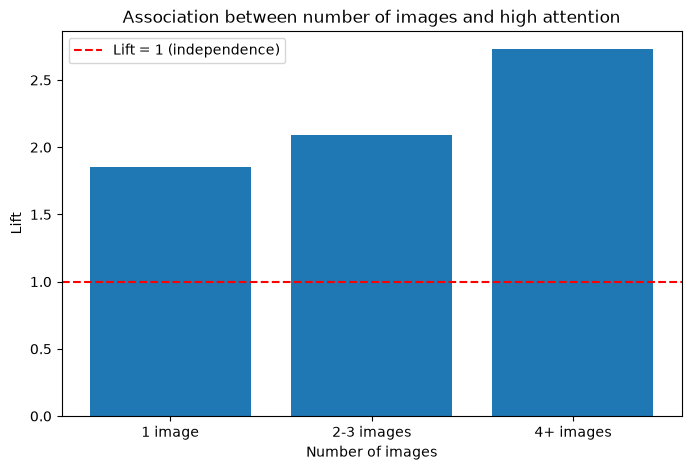

In [48]:
high_images = image_comparison[
    image_comparison["Attention_category"] == "High"
].copy()

plt.figure(figsize=(8, 5))

plt.bar(
    high_images["Image_category"],
    high_images["lift"]
)

plt.axhline(
    y=1,
    color="red",
    linestyle="--",
    label="Lift = 1 (independence)"
)

plt.xlabel("Number of images")
plt.ylabel("Lift")
plt.title("Association between number of images and high attention")
plt.legend()

plt.show()

So, the category that gets a higher positive association with getting High attention is 4+ images. However, the other categories also show some positive association with it, so they can not be discarded.

#### Comparing videos categories

In [49]:
# Extracting only rules containing images
video_rules = attention_rules_001[
    (attention_rules_001["antecedents"].apply(len) == 1) &
    (attention_rules_001["antecedents"].apply(lambda x: any(item.startswith("Videos=") for item in x)))
].copy()
display(video_rules.sort_values("lift", ascending = False))
print(f"{len(video_rules)} rules are only based on the video category")

,antecedents,consequents,antecedent support,consequent support,support,confidence,lift,representativity,leverage,conviction,zhangs_metric,jaccard,certainty,kulczynski
68,frozenset({Videos=1+ videos}),frozenset({Attention=Medium}),0.015337,0.134784,0.004259,0.277694,2.060293,1.0,0.002192,1.197853,0.522648,0.029199,0.165173,0.154647
80,frozenset({Videos=1+ videos}),frozenset({Attention=High}),0.015337,0.093242,0.001741,0.113506,1.217324,1.0,0.000311,1.022858,0.181307,0.016294,0.022347,0.066088
3,frozenset({Videos=No Videos}),frozenset({Attention=Low}),0.984663,0.771974,0.762637,0.774516,1.003292,1.0,0.002503,1.011272,0.213961,0.767240,0.011146,0.881210
15,frozenset({Videos=No Videos}),frozenset({Attention=Medium}),0.984663,0.134784,0.130525,0.132558,0.983485,1.0,-0.002192,0.997434,-0.522648,0.131987,-0.002573,0.550479
55,frozenset({Videos=1+ videos}),frozenset({Attention=Low}),0.015337,0.771974,0.009337,0.608800,0.788627,1.0,-0.002503,0.582888,-0.213961,0.012002,-0.715594,0.310448


5 rules are only based on the video category


In [50]:
video_rules["Video_category"] = video_rules["antecedents"].apply(
    lambda x: list(x)[0].replace("Videos=", "")
)

video_rules["Attention_category"] = video_rules["consequents"].apply(
    lambda x: list(x)[0].replace("Attention=", "")
)

video_comparison = video_rules[
    [
        "Video_category",
        "Attention_category",
        "support",
        "confidence",
        "lift"
    ]
].copy()

video_comparison = video_comparison.sort_values(
    ["Attention_category", "Video_category"]
)

display(video_comparison)

,Video_category,Attention_category,support,confidence,lift
80,1+ videos,High,0.001741,0.113506,1.217324
55,1+ videos,Low,0.009337,0.608800,0.788627
3,No Videos,Low,0.762637,0.774516,1.003292
68,1+ videos,Medium,0.004259,0.277694,2.060293
15,No Videos,Medium,0.130525,0.132558,0.983485


In this case not plotting as there are fewer rules. But it is seen that there is a high positive association between entries containing 1+ videos and High or Medium attention.   
Remarking that no videos is only associated with Low attention.

#### Comparing combination of videos and images

In [51]:
# Extracting only rules containing image + video antecendents
ImgVid_rules = attention_rules_001[
    (attention_rules_001["antecedents"].apply(len) == 2) &
    (attention_rules_001["antecedents"].apply(lambda x: any(item.startswith("Videos=") for item in x)))&
    (attention_rules_001["antecedents"].apply(lambda x: any(item.startswith("Images=") for item in x)))
].copy()
display(ImgVid_rules.sort_values("lift", ascending = False))
print(f"{len(ImgVid_rules)} rules are based on both video and image categories")

,antecedents,consequents,antecedent support,consequent support,support,confidence,lift,representativity,leverage,conviction,zhangs_metric,jaccard,certainty,kulczynski
78,"frozenset({Videos=No Videos, Images=4+ images})",frozenset({Attention=High}),0.007651,0.093242,0.001946,0.254326,2.727586,1.0,0.001232,1.216025,0.638259,0.019666,0.177648,0.137598
66,"frozenset({Videos=No Videos, Images=2-3 images})",frozenset({Attention=High}),0.030434,0.093242,0.005914,0.194313,2.083964,1.0,0.003076,1.125447,0.536472,0.050217,0.111464,0.128868
74,"frozenset({Images=No images, Videos=1+ videos})",frozenset({Attention=Medium}),0.014126,0.134784,0.003904,0.276350,2.050320,1.0,0.002000,1.195628,0.519611,0.026921,0.163619,0.152656
61,"frozenset({Videos=No Videos, Images=2-3 images})",frozenset({Attention=Medium}),0.030434,0.134784,0.007688,0.252610,1.874189,1.0,0.003586,1.157651,0.481077,0.048802,0.136182,0.154824
47,"frozenset({Videos=No Videos, Images=1 image})",frozenset({Attention=High}),0.154281,0.093242,0.026723,0.173209,1.857626,1.0,0.012337,1.096720,0.545901,0.121027,0.088190,0.229903
39,"frozenset({Videos=No Videos, Images=1 image})",frozenset({Attention=Medium}),0.154281,0.134784,0.035589,0.230674,1.711439,1.0,0.014794,1.124642,0.491530,0.140402,0.110828,0.247358
83,"frozenset({Videos=No Videos, Images=4+ images})",frozenset({Attention=Medium}),0.007651,0.134784,0.001695,0.221503,1.643393,1.0,0.000663,1.111393,0.394521,0.012042,0.100228,0.117038
86,"frozenset({Images=No images, Videos=1+ videos})",frozenset({Attention=High}),0.014126,0.093242,0.001542,0.109149,1.170598,1.0,0.000225,1.017856,0.147824,0.014569,0.017543,0.062842
8,"frozenset({Images=No images, Videos=No Videos})",frozenset({Attention=Low}),0.792297,0.771974,0.649825,0.820178,1.062443,1.0,0.038192,1.268065,0.282965,0.710621,0.211397,0.830974
28,"frozenset({Images=No images, Videos=No Videos})",frozenset({Attention=Medium}),0.792297,0.134784,0.085554,0.107982,0.801147,1.0,-0.021235,0.969953,-0.544425,0.101665,-0.030977,0.371364


14 rules are based on both video and image categories


In [52]:
ImgVid_rules["Video_category"] = ImgVid_rules["antecedents"].apply(
    lambda x: list(x)[0].replace("Videos=", "")
)
ImgVid_rules["Attention_category"] = ImgVid_rules["consequents"].apply(
    lambda x: list(x)[0].replace("Attention=", "")
)
ImgVid_rules["Image_category"] = ImgVid_rules["antecedents"].apply(
    lambda x: list(x)[1].replace("Images=", "")
)

Img_Vid_comparison = ImgVid_rules[
    [
        "Image_category",
        "Video_category",
        "Attention_category",
        "support",
        "confidence",
        "lift"
    ]
].copy()

Img_Vid_comparison = Img_Vid_comparison.sort_values(
    ["Attention_category", "Image_category","Video_category"]
)

display(Img_Vid_comparison)

,Image_category,Video_category,Attention_category,support,confidence,lift
47,1 image,No Videos,High,0.026723,0.173209,1.857626
66,2-3 images,No Videos,High,0.005914,0.194313,2.083964
78,4+ images,No Videos,High,0.001946,0.254326,2.727586
86,Videos=1+ videos,Images=No images,High,0.001542,0.109149,1.170598
20,1 image,No Videos,Low,0.091969,0.596117,0.772198
52,2-3 images,No Videos,Low,0.016832,0.553076,0.716444
71,4+ images,No Videos,Low,0.004010,0.524171,0.679001
57,Videos=1+ videos,Images=No images,Low,0.008680,0.614501,0.796012
8,Videos=No Videos,Images=No images,Low,0.649825,0.820178,1.062443
39,1 image,No Videos,Medium,0.035589,0.230674,1.711439


#### Visualizing the rules

In [53]:
all_attention_rules = attention_rules_001.copy()

all_attention_rules["Attention_category"] = (
    all_attention_rules["consequents"].apply(
        lambda x: next(
            item.replace("Attention=", "")
            for item in x
            if item.startswith("Attention=")
        )
    )
)

all_attention_rules["Rule_category"] = (
    all_attention_rules["antecedents"].apply(
        lambda x: " + ".join(
            item.replace("Images=", "Img: ")
                .replace("Videos=", "Vid: ")
            for item in sorted(x)
        )
    )
)

In [55]:
rule_categories = all_attention_rules["Rule_category"].unique()

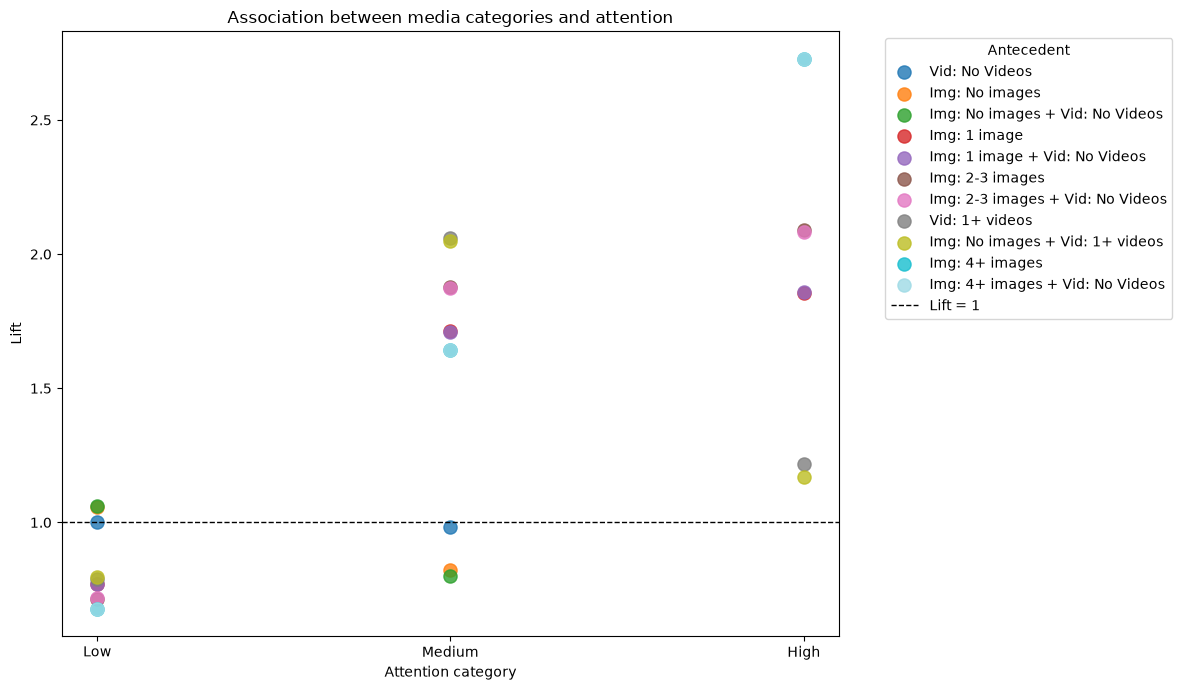

In [56]:
attention_order = ["Low", "Medium", "High"]

x_positions = {
    "Low": 0,
    "Medium": 1,
    "High": 2
}

colors = plt.cm.tab20(
    np.linspace(0, 1, len(rule_categories))
)

fig, ax = plt.subplots(figsize=(12, 7))

for color, rule_category in zip(colors, rule_categories):

    subset = all_attention_rules[
        all_attention_rules["Rule_category"] == rule_category
    ]

    x = subset["Attention_category"].map(x_positions)

    ax.scatter(
        x,
        subset["lift"],
        color=color,
        s=90,
        alpha=0.8,
        label=rule_category
    )

ax.axhline(
    y=1,
    color="black",
    linestyle="--",
    linewidth=1,
    label="Lift = 1"
)

ax.set_xticks([0, 1, 2])
ax.set_xticklabels(attention_order)

ax.set_xlabel("Attention category")
ax.set_ylabel("Lift")
ax.set_title("Association between media categories and attention")

ax.legend(
    title="Antecedent",
    bbox_to_anchor=(1.05, 1),
    loc="upper left"
)

plt.tight_layout()
plt.show()

From this visualization, we can see that:
- High attention shows the strongest positive associations. Remarking associations with entries containing any number of images.
- The opposite is observed for Low attention associations, as it shows negative associations with the itemsets containing large number of images or some videos. So it can be said that entries containing images are negatively associated with Low attention.
- Images seem to be a better discriminative feature than videos. When only video is taking into account, association with attention is seen as almost independent.
- Entries containing no images and no videos are slighlty associated with Low attention, while they are negatively associated with Medium attention.

### ANALYSING HIGH ATTENTION RULES   
As our aim is to understand what do entries receiving high attention contain we are focussing now on the rules leading to high attention

In [57]:
high_rules = all_attention_rules[
    all_attention_rules["Attention_category"] == "High"].copy()

high_rules = high_rules.sort_values(
    ["lift", "confidence"],
    ascending=False)

display(
    high_rules[["Rule_category", "support", "confidence", "lift"]])

,Rule_category,support,confidence,lift
76,Img: 4+ images,0.001954,0.254364,2.727986
78,Img: 4+ images + Vid: No Videos,0.001946,0.254326,2.727586
64,Img: 2-3 images,0.005969,0.194912,2.090388
66,Img: 2-3 images + Vid: No Videos,0.005914,0.194313,2.083964
47,Img: 1 image + Vid: No Videos,0.026723,0.173209,1.857626
44,Img: 1 image,0.026858,0.172977,1.855134
80,Vid: 1+ videos,0.001741,0.113506,1.217324
86,Img: No images + Vid: 1+ videos,0.001542,0.109149,1.170598


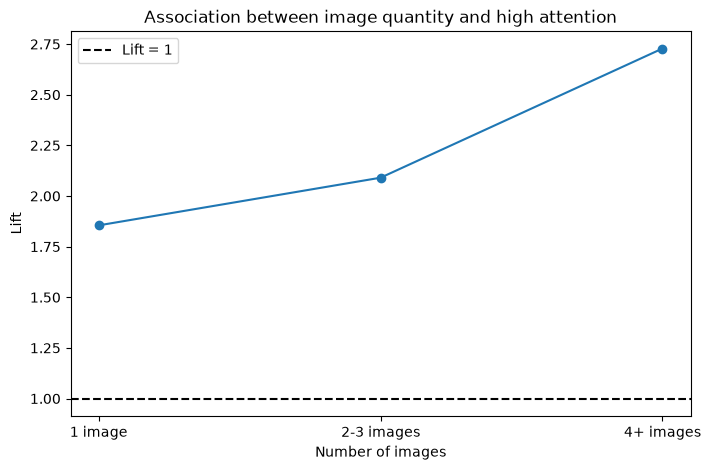

In [58]:
high_images = image_comparison[
    image_comparison["Attention_category"] == "High"].copy()

order = ["No images", "1 image", "2-3 images", "4+ images"]

high_images["Image_category"] = pd.Categorical(
    high_images["Image_category"],
    categories=order,
    ordered=True)

high_images = high_images.sort_values("Image_category")

plt.figure(figsize=(8, 5))

plt.plot(
    high_images["Image_category"],
    high_images["lift"],
    marker="o")

plt.axhline(
    1,
    color="black",
    linestyle="--",
    label="Lift = 1")

plt.xlabel("Number of images")
plt.ylabel("Lift")
plt.title("Association between image quantity and high attention")

plt.legend()
plt.show()

Entries containing images are positively associated with getting high attention, and this association increases when more images are added.  
However in our data there are many few entries containing this pattern this is why a low support is observed.

### GENERAL RULE VISUALIZATION  
To get a general visualization of all the rules we are plotting them showing their lift and their confidence values. It is important in these cases to identify which rules show high lift but low confidence or the opposite.

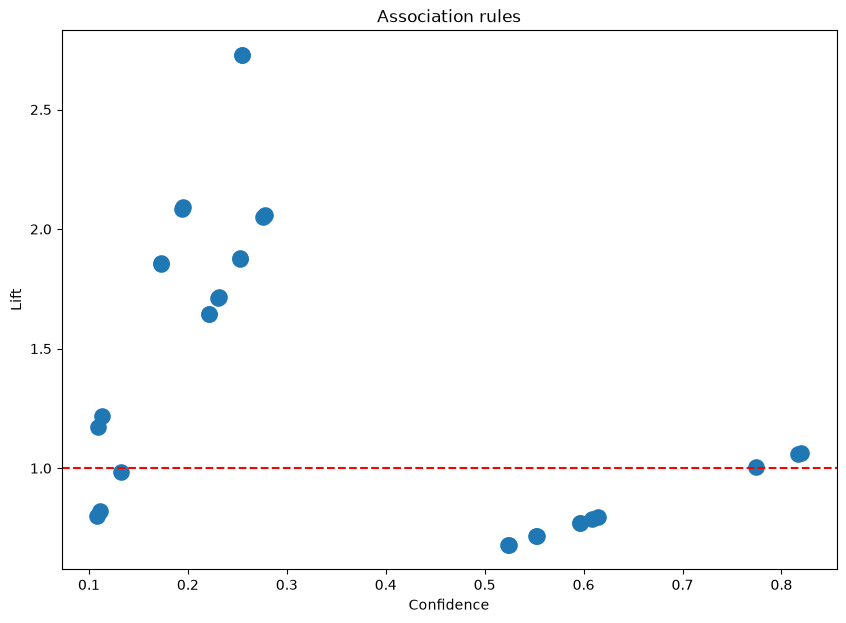

In [59]:
plot_rules = attention_rules_001.copy()

plot_rules["Rule"] = plot_rules["antecedents"].apply(
    lambda x: " + ".join(sorted(x))
)

fig, ax = plt.subplots(figsize=(10, 7))

ax.scatter(
    plot_rules["confidence"],
    plot_rules["lift"],
    s=120
)

ax.axhline(
    y=1,
    color="red",
    linestyle="--"
)

ax.set_xlabel("Confidence")
ax.set_ylabel("Lift")
ax.set_title("Association rules")

plt.show()

Making a table to easily visualize confidence and lift values

In [60]:
summary_table = (all_attention_rules.pivot(
    index="Rule_category",
    columns="Attention_category",
    values=["lift", "confidence"]
)).round(3)

summary_table

lift               confidence              
Attention_category                 High    Low Medium       High    Low Medium
Rule_category                                                                 
Img: 1 image                      1.855  0.772  1.714      0.173  0.596  0.231
Img: 1 image + Vid: No Videos     1.858  0.772  1.711      0.173  0.596  0.231
Img: 2-3 images                   2.090  0.715  1.877      0.195  0.552  0.253
Img: 2-3 images + Vid: No Videos  2.084  0.716  1.874      0.194  0.553  0.253
Img: 4+ images                    2.728  0.679  1.644      0.254  0.524  0.222
Img: 4+ images + Vid: No Videos   2.728  0.679  1.643      0.254  0.524  0.222
Img: No images                      NaN  1.058  0.823        NaN  0.817  0.111
Img: No images + Vid: 1+ videos   1.171  0.796  2.050      0.109  0.615  0.276
Img: No images + Vid: No Videos     NaN  1.062  0.801        NaN  0.820  0.108
Vid: 1+ videos                    1.217  0.789  2.060      0.114  0.609  0.278
Vid: No Videos                      NaN  1.003  0.983        NaN  0.775  0.133

Finally we generated a heatmap to make a more understandable interpretation of which rules show positive association.

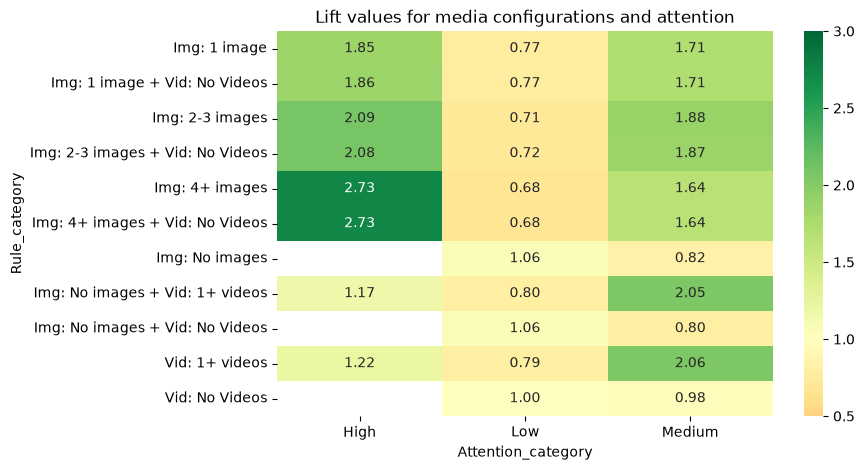

In [61]:
summary_table_lift = (all_attention_rules.pivot(
    index="Rule_category",
    columns="Attention_category",
    values="lift"
)).round(3)

summary_table_lift
plt.figure(figsize=(8, 5))

sns.heatmap(
    summary_table_lift,
    annot=True,
    cmap="RdYlGn",
    center=1,
    vmax=3,
    vmin=0.5,
    fmt=".2f"
)

plt.title(
    "Lift values for media configurations and attention"
)

plt.show()